# Identification des utilisateurs de Copilote

**MOD 7.2 – Introduction à la science des données – BE**

Groupe : Achraf BITAR.

**Objectif.** À partir des traces d'utilisation du logiciel Copilote (Infologic), retrouver quel utilisateur a réalisé une session. C'est une tâche de **classification supervisée** : chaque session est un **individu** décrit par des **variables explicatives** $X$, et sa **classe** $Z$ est l'utilisateur.

## 1. Chargement des données

In [ ]:
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)   # pour sauvegarder les graphiques du rapport

Chaque ligne d'un fichier est une **session** : utilisateur, navigateur, puis les actions, séparées par des virgules. La fonction `read_ds` du notebook d'indications crée un tableau de 14 470 colonnes presque vides. On lit plutôt le fichier **ligne par ligne** (`readlines`) et on garde, pour chaque session, la **liste de ses actions** dans une seule colonne.

In [2]:
def lire_fichier(nom):
    """Lit data/<nom>.csv ligne par ligne : une ligne = une session."""
    sessions = []
    with open(f"data/{nom}.csv", encoding="utf-8") as f:
        for ligne in f.readlines():
            morceaux = ligne.rstrip("\n").split(",")
            if nom == "train":
                sessions.append({"util": morceaux[0], "navigateur": morceaux[1], "actions": morceaux[2:]})
            else:
                sessions.append({"navigateur": morceaux[0], "actions": morceaux[1:]})
    return pd.DataFrame(sessions)


train = lire_fichier("train")
test = lire_fichier("test")
print("train :", train.shape, "| test :", test.shape)
train.head()

train : (3279, 3) | test : (324, 2)


,util,navigateur,actions
0,nuh,Firefox,[Création d'un écran(infologic.core.accueil.Ac...
1,muz,Google Chrome,[Création d'un écran(infologic.core.gui.contro...
2,zrx,Microsoft Edge,[Affichage d'une dialogue(infologic.core.gui.c...
3,pou,Firefox,[Création d'un écran(infologic.core.gui.contro...
4,ald,Google Chrome,[Affichage d'une dialogue(infologic.acti.modul...


In [3]:
train.loc[0, "actions"][:15]

["Création d'un écran(infologic.core.accueil.AccueilController)",
 "Affichage d'une dialogue",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Affichage d'une dialogue",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)",
 't5',
 "Exécution d'un bouton(MAINT)",
 "Affichage d'une dialogue",
 "Fermeture d'une dialogue",
 'Double-clic',
 "Exécution d'un bouton",
 "Lancement d'une stat(infologic.core.gui.controllers.nested.homeview.InputFormHomeView)"]

## 2. Statistiques simples

### 2.1 Les navigateurs (variable catégorielle)

In [4]:
pd.DataFrame({"train": train["navigateur"].value_counts(),
              "test": test["navigateur"].value_counts()})

,train,test
navigateur,,
Firefox,1466,147
Google Chrome,1339,133
Microsoft Edge,451,42
Opera,23,2


In [5]:
navigateur_par_utilisateur = pd.crosstab(train["util"], train["navigateur"])
nb_navigateurs = (navigateur_par_utilisateur > 0).sum(axis=1)
print("Utilisateurs ayant utilisé plus d'un navigateur :", (nb_navigateurs > 1).sum())
print("Nombre d'utilisateurs par navigateur :")
print((navigateur_par_utilisateur > 0).sum())

Utilisateurs ayant utilisé plus d'un navigateur : 0
Nombre d'utilisateurs par navigateur :
navigateur
Firefox           114
Google Chrome      93
Microsoft Edge     39
Opera               1
dtype: int64


**Analyse.** Le mode est Firefox ; Opera est très rare. Surtout, chaque utilisateur utilise toujours le même navigateur (114 sous Firefox, 93 sous Chrome, 39 sous Edge, un seul sous Opera) : le navigateur élimine d'office beaucoup de classes, c'est une variable explicative à garder.

### 2.2 La classe à prédire : l'utilisateur

Nombre de classes (utilisateurs) : 247
count    247.0
mean      13.3
std        8.9
min        4.0
25%        7.0
50%       12.0
75%       16.0
max       75.0
Name: count, dtype: float64


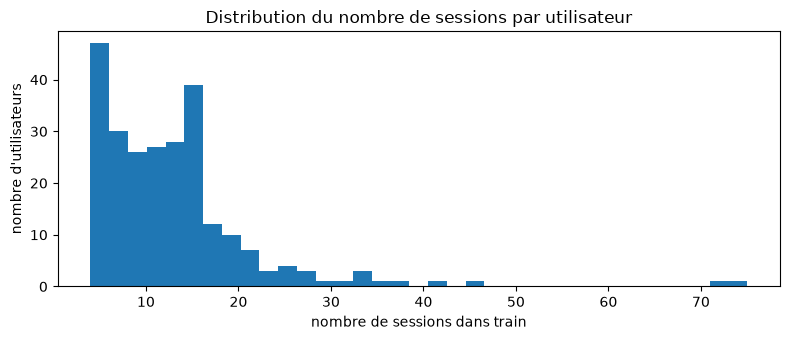

In [6]:
sessions_par_utilisateur = train["util"].value_counts()
print("Nombre de classes (utilisateurs) :", sessions_par_utilisateur.size)
print(sessions_par_utilisateur.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(sessions_par_utilisateur, bins=35)
ax.set_xlabel("nombre de sessions dans train")
ax.set_ylabel("nombre d'utilisateurs")
ax.set_title("Distribution du nombre de sessions par utilisateur")
plt.tight_layout()
plt.savefig("figures/sessions_par_utilisateur.png", dpi=150)
plt.show()

*Analyse :* La distrubution du nombre de sessions par utilisateur est déséquilibrée donc le taux de bon classement seule n'est pas suffisant, on utilise aussi la F mesure macro

### 2.3 Longueur et durée des sessions

Un marqueur `tXX` indique le temps écoulé depuis le début de la session (un toutes les 5 secondes).

In [7]:
def est_marqueur_temps(valeur):
    return re.fullmatch(r"t\d+", valeur) is not None


def resume_session(actions):
    temps = [int(a[1:]) for a in actions if est_marqueur_temps(a)]
    nb_actions = len(actions) - len(temps)
    return pd.Series({"nb_actions": nb_actions, "duree_s": max(temps) if temps else 0})


resume_train = train["actions"].apply(resume_session)
resume_test = test["actions"].apply(resume_session)
pd.concat({"train": resume_train.describe(), "test": resume_test.describe()}, axis=1).round(1)

train                test        
      nb_actions  duree_s nb_actions duree_s
count     3279.0   3279.0      324.0   324.0
mean       692.4    751.5      662.3   739.9
std       1005.9   1006.3      811.5   920.9
min          0.0      5.0        9.0    20.0
25%        153.0    185.0      161.5   190.0
50%        340.0    395.0      365.0   407.5
75%        818.5    945.0      819.2   935.0
max      11977.0  11790.0     6203.0  7110.0

**Analyse.** La session médiane contient 340 actions et dure 395 s, mais la dispersion est énorme. La moyenne (692 actions) est deux fois plus grande que la médiane : la distribution est très asymétrique, avec quelques sessions très longues qui tirent la moyenne vers le haut.

Comparer des comptes bruts n'aurait donc pas de sens. Pour construire les caractéristiques, on utilisera, des **taux** (actions par minute) et une **transformation logarithmique** pour les variables très étalées.

Le test ressemble au train (médianes et quartiles proches). On remarque aussi des sessions presque vides (minimum à 0 action) : on les étudiera à l'étape suivante, avec les **données aberrantes**.